# Shape Transformation using Variational Implicit Functions Notebook Implementation

Notebook implementation by Andy Thai

Sample implementation: https://github.com/fiji/VIB/blob/master/src/main/java/Implicit_Interpolate_Binary.java

Set up our interpolation function f(x):

$
f(x) = \sum_{j=1}^k d_j \phi(x - c_j) + P(x) 
$

<br>

We want to solve for $d_j$ and the coefficients of $P(x)$. To solve for $d_j$, we can substitute the right side of the above equation for $f(\textbf{c}_i)$ for the constraints $h_i = f(\textbf{c}_i)$ to get the below equation, where $h_i$ is the height value:

$
h_i = \sum_{j=1}^k d_j \phi(c_i - c_j) + P(c_i) 
$

<br>
We can represent this equation as the matrix in the 3D interpolation case, where $h_i$ is corresponding x or y coordinate, depending on whether you are solving for $f'_{x}$ or $f'_{y}$:

$
\begin{bmatrix}
\phi_{11} & \phi_{12} & \ldots & \phi_{1k} & 1 & c_1^x & c_1^y & c_1^z \\
\phi_{21} & \phi_{22} & \ldots & \phi_{2k} & 1 & c_2^x & c_2^y & c_2^z \\
\vdots & \vdots & \ldots & \vdots & \vdots & \vdots & \vdots & \vdots \\
\phi_{k1} & \phi_{k2} & \ldots & \phi_{kk} & 1 & c_k^x & c_k^y & c_k^z \\
1 & 1 & \ldots & 1 & 0 & 0 & 0 & 0 \\
c_1^x & c_2^x & \ldots & c_k^x & 0 & 0 & 0 & 0 \\
c_1^y & c_2^y & \ldots & c_k^y & 0 & 0 & 0 & 0 \\
c_1^z & c_2^z & \ldots & c_k^z & 0 & 0 & 0 & 0 \\
\end{bmatrix}
\begin{bmatrix}
d_1 \\ 
d_2 \\
\vdots \\
d_k \\
p_0 \\
p_1 \\
p_2 \\
p_3 \\
\end{bmatrix}
=
\begin{bmatrix}
h_1 \\ 
h_2 \\
\vdots \\
h_k \\
0 \\
0 \\
0 \\
0 \\
\end{bmatrix}
$

<br>
Let $\phi_{ij} = \phi(\textbf{c}_i - \textbf{c}_j)$

$p_0, p_1, p_2, p_3$ can also be written as $p_0, p_x, p_y, p_z$ respectively.



## Import libraries

In [1]:
# Standard library test
import time
from pprint import pprint

# Third-party libraries
import numpy as np
import matplotlib.pyplot as plt
import scipy
from jupyterthemes import jtplot; jtplot.style()

# My libraries
from implicit import ImplicitFunction
import utils

## Setup sample 3D example

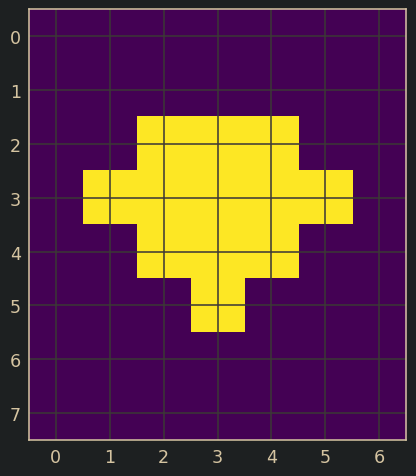

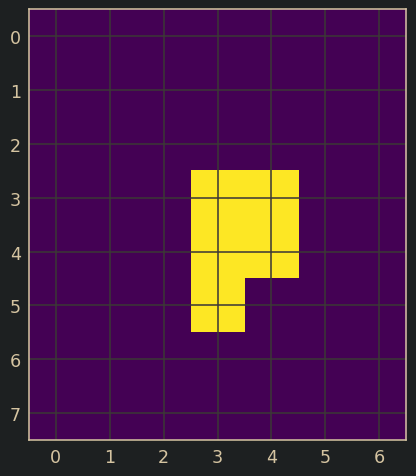

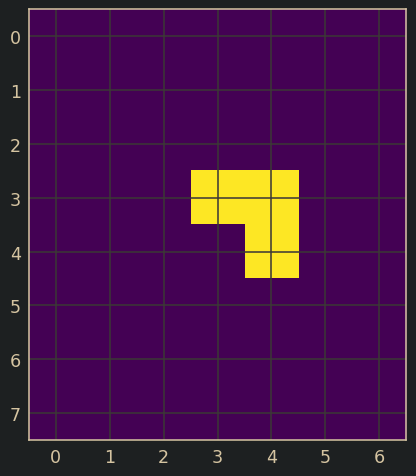

In [2]:
filepath = "data/npy/lv.npy"
volume = np.load(filepath)

m1 = np.array([[0, 0, 0, 0, 0, 0, 0],
               [0, 0, 0, 0, 0, 0, 0],
               [0, 0, 1, 1, 1, 0, 0],
               [0, 1, 1, 1, 1, 1, 0],
               [0, 0, 1, 1, 1, 0, 0],
               [0, 0, 0, 1, 0, 0, 0],
               [0, 0, 0, 0, 0, 0, 0],
               [0, 0, 0, 0, 0, 0, 0]])
m2 = np.array([[0, 0, 0, 0, 0, 0, 0],
               [0, 0, 0, 0, 0, 0, 0],
               [0, 0, 0, 0, 0, 0, 0],
               [0, 0, 0, 1, 1, 0, 0],
               [0, 0, 0, 1, 1, 0, 0],
               [0, 0, 0, 1, 0, 0, 0],
               [0, 0, 0, 0, 0, 0, 0],
               [0, 0, 0, 0, 0, 0, 0]])
m3 = np.array([[0, 0, 0, 0, 0, 0, 0],
               [0, 0, 0, 0, 0, 0, 0],
               [0, 0, 0, 0, 0, 0, 0],
               [0, 0, 0, 1, 1, 0, 0],
               [0, 0, 0, 0, 1, 0, 0],
               [0, 0, 0, 0, 0, 0, 0],
               [0, 0, 0, 0, 0, 0, 0],
               [0, 0, 0, 0, 0, 0, 0]])
M = np.array([m1, m2, m3])
plt.imshow(m1); plt.show()
plt.imshow(m2); plt.show()
plt.imshow(m3); plt.show()

### Test implementation for 3D interpolation input

DEBUG: Creating constraints.
DEBUG: Finished creating constraints.
Elapsed time: 0.011616945266723633

DEBUG: Creating matrix.


Creating matrix:   0%|          | 0/100 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 0.01315164566040039

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 0.00032520294189453125
Elapsed time: 0.15088438987731934


Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

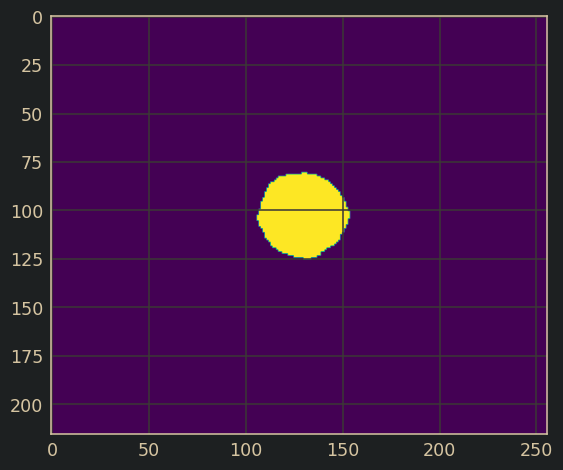

Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

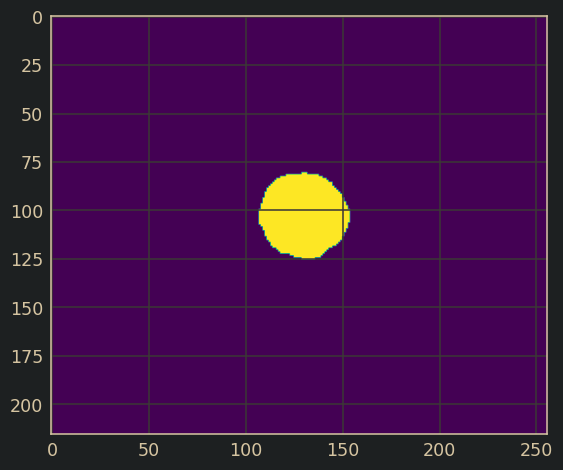

Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

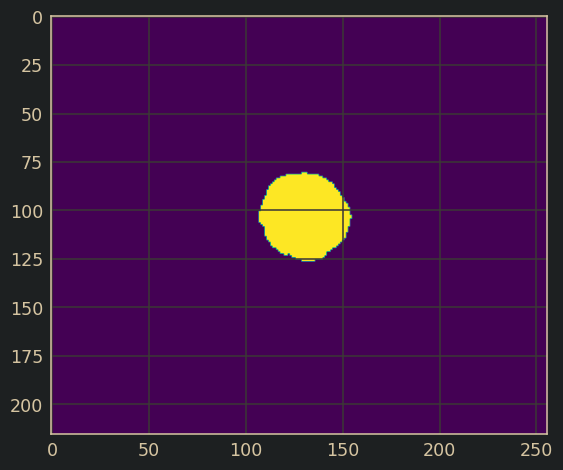

Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

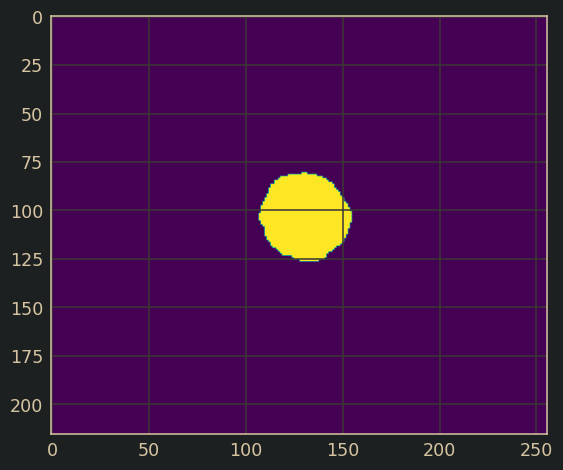

In [3]:
# Setup 3D volume
M = volume[5, 3:5, :, :]

start = time.time()
imp = ImplicitFunction(M, tmax=1)
end = time.time() - start
print(f"Elapsed time: {end}")

# Interpolate 2D image at some parametrization t
#start = time.time()
img = imp.interpolate(0)
plt.imshow(img); plt.show()
#end = time.time() - start
#print(f"Elapsed time: {end}")
img = imp.interpolate(0.25)
plt.imshow(img); plt.show()

img = imp.interpolate(0.75)
plt.imshow(img); plt.show()

img = imp.interpolate(1.0)
plt.imshow(img); plt.show()

# Save to file
imp.save("pickle/matrix.pickle")

imp = ImplicitFunction(M[0], tmax=1)
b = imp.b[:, :2]
n = imp.n[:, :2]
plt.imshow(M[0])
plt.scatter(b[:, 0], b[:, 1], color='r')
plt.scatter(n[:, 0], n[:, 1], color='g')

imp.M

## Setup sample 4D input

In [13]:
volume.shape

(30, 10, 216, 256)

In [4]:
# Setup 4D volume
curr_volume = volume[3:5, 3:7, :, :]
#curr_volume = volume[:, :, :, :]
#curr_volume = volume[:, :, :, :]
print(f"Input volume shape: {curr_volume.shape}")
imp = ImplicitFunction(curr_volume)

# Save to file
imp.save("pickle/volume.pickle")

Input volume shape: (2, 4, 216, 256)
DEBUG: Creating constraints.
DEBUG: Finished creating constraints.
Elapsed time: 0.05336761474609375

DEBUG: Creating matrix.


Creating matrix:   0%|          | 0/502 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 0.08174610137939453

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 0.0016446113586425781


plt.imshow(curr_volume)
b = imp.b[:, :2]
n = imp.n[:, :2]
plt.scatter(b[:, 0], b[:, 1], color='r')
plt.scatter(n[:, 0], n[:, 1], color='g')

### Show original input volume slices

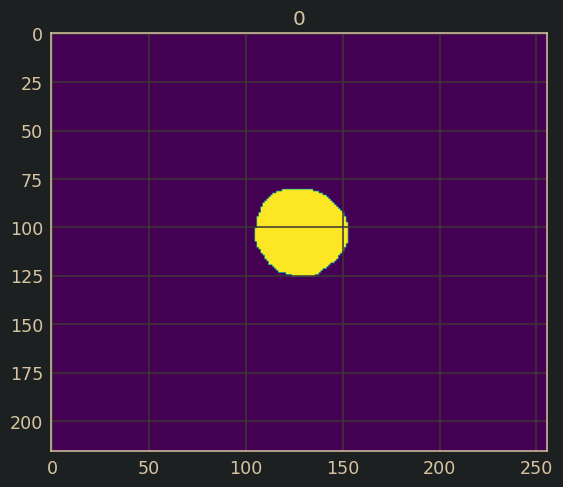

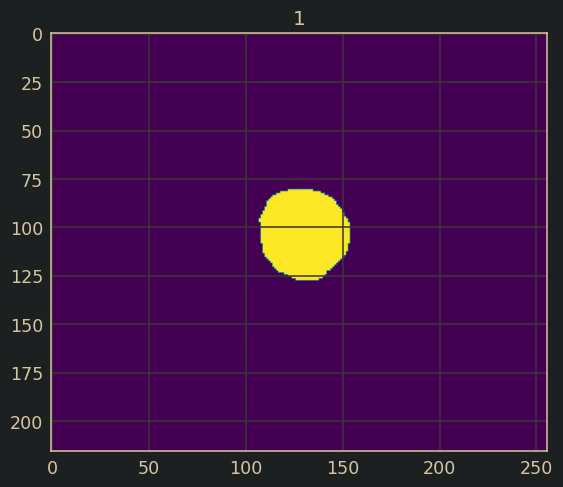

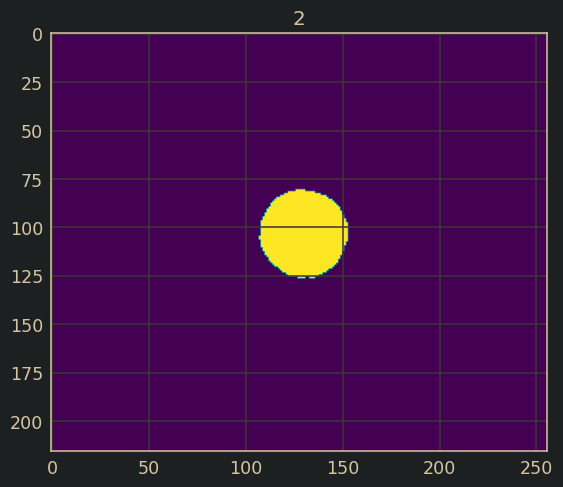

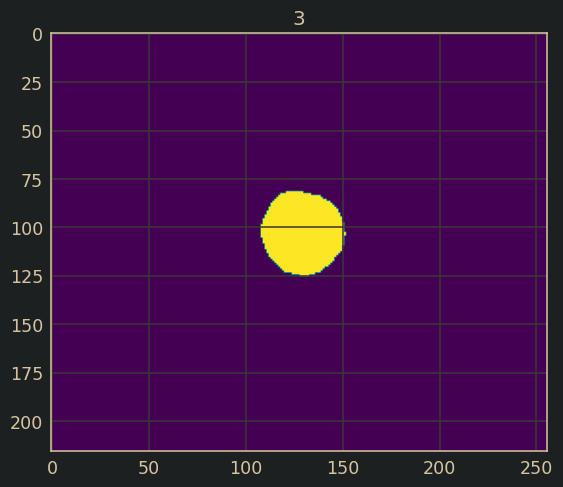

In [5]:
# Show slices for original volume 0
for idx in range(curr_volume.shape[1]):
    plt.imshow(curr_volume[0][idx])
    plt.title(idx)
    plt.show()

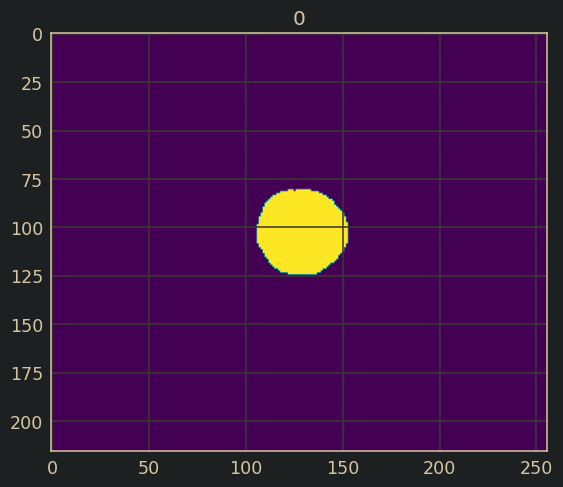

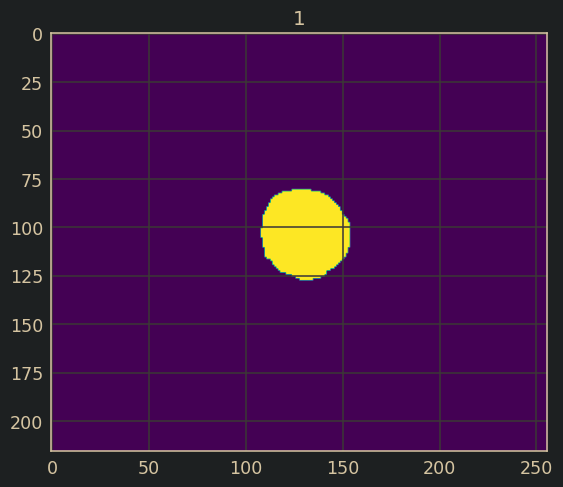

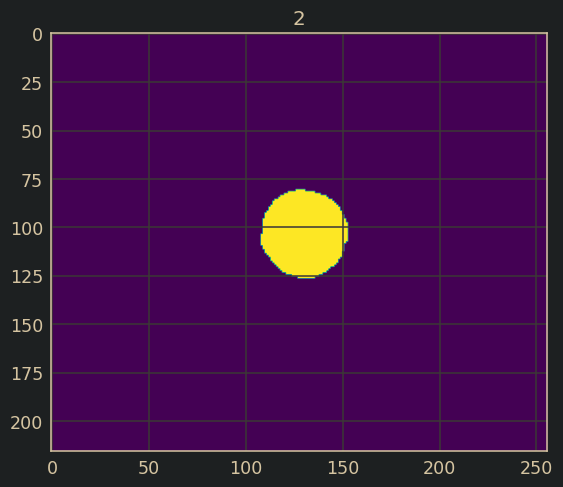

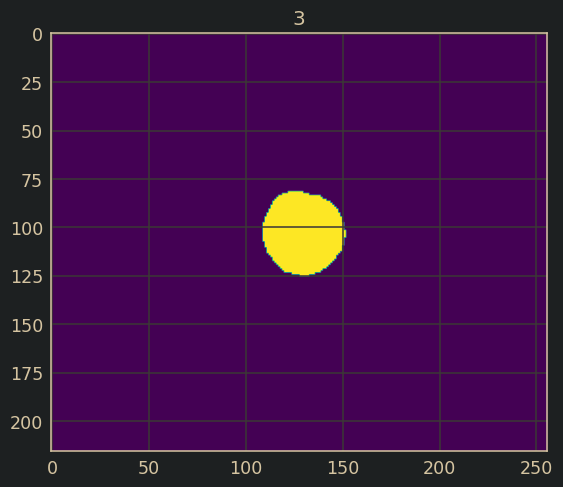

In [6]:
# Show slices for original volume 1
for idx in range(curr_volume.shape[1]):
    plt.imshow(curr_volume[-1][idx])
    plt.title(idx)
    plt.show()

### Interpolate results for 4D input

In [8]:
# Interpolate a 4D volume at some parametrization t
start = time.time()
vol = imp.interpolate(0.5)
end = time.time() - start
print(f"Interpolated volume shape: {vol.shape}")
print(f"Elapsed time: {end}")

Output dimensions: (4, 216, 256)
Threshold: 0.0


Interpolating volume stack:   0%|          | 0/864 [00:00<?, ?it/s]

Interpolated volume shape: (4, 216, 256)
Elapsed time: 32.367427825927734


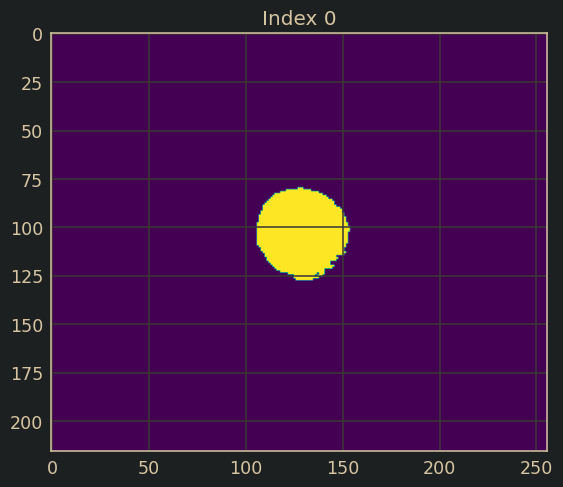

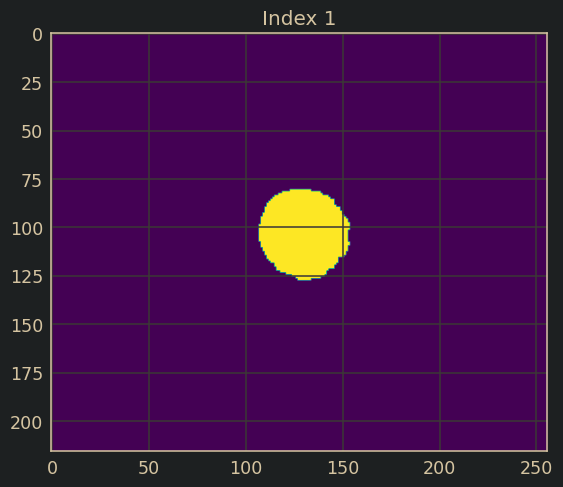

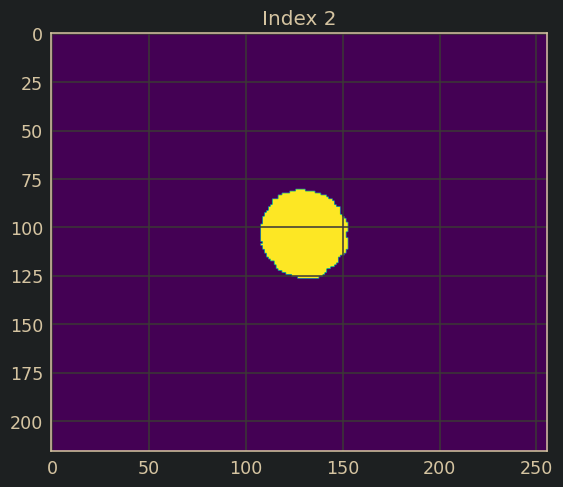

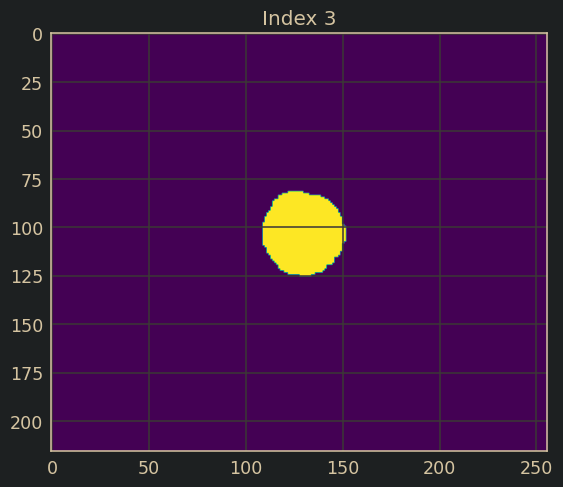

In [10]:
# Show slices for generated volume
for idx in range(vol.shape[0]):
    plt.imshow(vol[idx])
    plt.title(f"Index {idx}")
    plt.show()

## Misc.

In [12]:
sum(imp.d)

1.8707257964933888e-14

In [10]:
curr_volume.shape

(30, 10, 216, 256)